# 🩺 Transformer + Explainable AI Based Cuffless Blood Pressure Estimation using PPG

---

## 📌 Project Objective

The objective of this project is to estimate a person's blood pressure without using a traditional inflatable cuff.

Instead of measuring blood pressure directly, we use a physiological signal called the **Photoplethysmogram (PPG)**.

The PPG signal is processed using signal processing techniques and converted into scalogram images.

These images are then given to a Transformer-based Deep Learning model that predicts:

- Systolic Blood Pressure (SBP)
- Diastolic Blood Pressure (DBP)

Finally, Explainable AI (XAI) techniques are used to understand how the model makes predictions.

---

## Workflow

MIMIC-IV Dataset

↓

Extract PPG

↓

Preprocessing

↓

Filtering

↓

Heart Rate

↓

Continuous Wavelet Transform

↓

Scalogram

↓

Vision Transformer

↓

Blood Pressure Prediction

↓

Explainable AI

↓

Evaluation

---

## Technologies Used

- Python
- NumPy
- Pandas
- Matplotlib
- SciPy
- WFDB
- PyTorch
- timm
- Captum
- SHAP


In [2]:
import os
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from scipy import signal

import wfdb

import pywt

from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

warnings.filterwarnings("ignore")

# Setting Random Seed

Random seed ensures that our experiment gives the same results every time we run the notebook.

In [3]:
# =====================================
# Project Configuration
# =====================================

PROJECT_NAME = "Transformer + XAI Cuffless BP Estimation"

RANDOM_SEED = 42

DATASET_VERSION = "MIMIC-IV Waveform Database 0.1.0"

PPG_CHANNEL_NAMES = [
    "PLETH",
    "PPG"
]

ABP_CHANNEL_NAMES = [
    "ABP",
    "ART"
]

OUTPUT_IMAGE_SIZE = (224, 224)

print(PROJECT_NAME)
print(DATASET_VERSION)

Transformer + XAI Cuffless BP Estimation
MIMIC-IV Waveform Database 0.1.0


In [4]:
SEED = 42

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random Seed Set Successfully!")

Random Seed Set Successfully!


In [5]:
folders = [
    "data/raw",
    "data/processed",
    "data/labels",
    "models",
    "outputs",
    "outputs/figures",
    "outputs/csv",
    "outputs/logs",
    "scalograms",
    "checkpoints",
    "notebooks"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("✅ Project folders created successfully!")

✅ Project folders created successfully!


# Section 7: Configure Dataset Path

In this section, we define the location of the MIMIC-IV Waveform Dataset.

Instead of writing the dataset path repeatedly throughout the notebook, we store it in one variable. This makes the notebook easier to maintain and allows the dataset location to be changed in a single place if needed.

In [6]:
from pathlib import Path

DATASET_PATH = Path(
    r"C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb"
)

print(DATASET_PATH)
print("Exists :", DATASET_PATH.exists())

C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb
Exists : True


In [7]:
import os

print("=" * 70)
print("MIMIC-IV Waveform Dataset")
print("=" * 70)

for item in sorted(os.listdir(DATASET_PATH)):
    print(item)

MIMIC-IV Waveform Dataset
0.1.0


In [8]:
from pathlib import Path

root = Path(DATASET_PATH)

print("=" * 70)
print("MIMIC-IV Folder Structure")
print("=" * 70)

for item in root.iterdir():
    print(item.name)

    if item.is_dir():
        print("--------------------------------------------------")

        count = 0

        for sub in item.iterdir():
            print("   └──", sub.name)

            count += 1

            if count >= 10:
                print("   ...")
                break

MIMIC-IV Folder Structure
0.1.0
--------------------------------------------------
   └── index.html
   └── LICENSE.txt
   └── RECORDS
   └── SHA256SUMS.txt
   └── waves


# Section 8 : Reading the RECORDS File

The MIMIC-IV Waveform Dataset contains thousands of waveform records.

Instead of manually searching every folder, the RECORDS file contains the relative path of every available waveform record.

In this section we will:

- Read the RECORDS file.
- Count the total number of waveform records.
- Display the first few records.

In [9]:
# ==========================================
# Read RECORDS File
# ==========================================

RECORDS_FILE = DATASET_PATH / "0.1.0" / "RECORDS"

print("RECORDS File:")
print(RECORDS_FILE)

print("\nExists :", RECORDS_FILE.exists())

RECORDS File:
C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\RECORDS

Exists : True


In [10]:
# Read all waveform record paths

with open(RECORDS_FILE, "r") as file:
    record_paths = file.read().splitlines()

print("=" * 70)
print("Total Waveform Records")
print("=" * 70)

print(len(record_paths))

Total Waveform Records
198


In [11]:
print("=" * 70)
print("First 20 Records")
print("=" * 70)

for i, record in enumerate(record_paths[:20], start=1):
    print(f"{i:02d}. {record}")

First 20 Records
01. waves/p100/p10014354/
02. waves/p100/p10019003/
03. waves/p100/p10020306/
04. waves/p100/p10039708/
05. waves/p100/p10079700/
06. waves/p100/p10082591/
07. waves/p101/p10100546/
08. waves/p101/p10112163/
09. waves/p101/p10126957/
10. waves/p102/p10209410/
11. waves/p103/p10303080/
12. waves/p104/p10494990/
13. waves/p105/p10560354/
14. waves/p106/p10680081/
15. waves/p108/p10882818/
16. waves/p109/p10952189/
17. waves/p110/p11013146/
18. waves/p111/p11109975/
19. waves/p113/p11320864/
20. waves/p113/p11392990/


# Section 9 : Finding WFDB Records

The RECORDS file only contains folder names.

Each folder may contain one or more WFDB records.

A WFDB record is usually composed of:

- .hea  (Header)
- .dat  (Signal)
- Optional annotation files

In this section we will:

1. Scan every record folder.
2. Find all WFDB header (.hea) files.
3. Build a list of actual waveform records.
4. Count the number of usable records.

In [12]:
from pathlib import Path

# Root folder containing waveform records
WAVE_ROOT = DATASET_PATH / "0.1.0"

print("Wave Root:")
print(WAVE_ROOT)

print("\nExists :", WAVE_ROOT.exists())

Wave Root:
C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0

Exists : True


In [13]:
import os

wfdb_records = []

for folder in record_paths:

    folder_path = WAVE_ROOT / folder

    if not folder_path.exists():
        continue

    for file in os.listdir(folder_path):

        if file.endswith(".hea"):

            record_name = file.replace(".hea", "")

            wfdb_records.append(folder_path / record_name)

print("=" * 70)
print("Total WFDB Records Found")
print("=" * 70)

print(len(wfdb_records))

Total WFDB Records Found
0


In [14]:
print("=" * 70)
print("First 10 WFDB Records")
print("=" * 70)

for record in wfdb_records[:10]:
    print(record)

First 10 WFDB Records


In [15]:
from pathlib import Path

first_folder = WAVE_ROOT / record_paths[0]

print("First Folder:")
print(first_folder)

print("\nContents:\n")

for item in first_folder.iterdir():
    print(item.name)
    

First Folder:
C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354

Contents:

81739927
index.html
RECORDS


In [16]:
from pathlib import Path

patient_folder = None

for item in first_folder.iterdir():

    if item.is_dir():

        patient_folder = item
        break

print(patient_folder)

C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927


In [17]:
print("=" * 70)
print("Files inside Patient Folder")
print("=" * 70)

for file in sorted(patient_folder.iterdir()):
    print(file.name)

Files inside Patient Folder
81739927.hea
81739927_0000.hea
81739927_0001.hea
81739927_0001e.dat
81739927_0001r.dat
81739927_0002.hea
81739927_0002e.dat
81739927_0002p.dat
81739927_0002r.dat
81739927_0003.hea
81739927_0003e.dat
81739927_0003p.dat
81739927_0003r.dat
81739927_0004.hea
81739927_0004p.dat
81739927_0004r.dat
81739927_0005.hea
81739927_0005e.dat
81739927_0005p.dat
81739927_0005r.dat
81739927_0006.hea
81739927_0006e.dat
81739927_0006p.dat
81739927_0006r.dat
81739927_0007.hea
81739927_0007e.dat
81739927_0007p.dat
81739927_0007r.dat
81739927_0008.hea
81739927_0008e.dat
81739927_0008p.dat
81739927_0008r.dat
81739927_0009.hea
81739927_0009e.dat
81739927_0009r.dat
81739927_0010.hea
81739927_0010e.dat
81739927_0010p.dat
81739927_0010r.dat
81739927_0011.hea
81739927_0011e.dat
81739927_0011r.dat
81739927_0012.hea
81739927_0012e.dat
81739927_0012p.dat
81739927_0012r.dat
81739927_0013.hea
81739927_0013e.dat
81739927_0013p.dat
81739927_0013r.dat
81739927_0014.hea
81739927_0014e.dat
81739

# Section 10 : Read First WFDB Header

Each patient folder contains one master header file.

The master header contains:

- Sampling Frequency
- Number of Segments
- Signal Information

We first inspect this header before reading waveform signals.

In [18]:
from pathlib import Path

# Find the master .hea file (ignore segmented files like _0001.hea)
master_header = None

for file in patient_folder.glob("*.hea"):
    if "_" not in file.stem:
        master_header = file
        break

print("=" * 70)
print("Master Header File")
print("=" * 70)

print(master_header)

Master Header File
C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927.hea


In [19]:
# Remove the .hea extension because WFDB expects only the record name
master_record = str(master_header.with_suffix(""))

print(master_record)

C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927


In [20]:
import wfdb

header = wfdb.rdheader(master_record)

print(header)

In [21]:
print("=" * 70)
print("Sampling Frequency")
print("=" * 70)

print(header.fs)

Sampling Frequency
62.4725


In [22]:
print("=" * 70)
print("Signal Names")
print("=" * 70)

print(header.sig_name)

Signal Names
None


In [23]:
print("=" * 70)
print("Record Name")
print("=" * 70)

print(header.record_name)

Record Name
81739927


In [24]:
print("=" * 70)
print("Number of Segments")
print("=" * 70)

print(header.n_seg)

Number of Segments
21


In [25]:
print("=" * 70)
print("Segment Names")
print("=" * 70)

print(header.seg_name)

Segment Names
['81739927_0000', '81739927_0001', '81739927_0002', '81739927_0003', '81739927_0004', '81739927_0005', '81739927_0006', '81739927_0007', '81739927_0008', '81739927_0009', '81739927_0010', '81739927_0011', '81739927_0012', '81739927_0013', '81739927_0014', '81739927_0015', '81739927_0016', '81739927_0017', '81739927_0018', '81739927_0019', '81739927_0020']


In [26]:
print("=" * 70)
print("Segment Lengths")
print("=" * 70)

print(header.seg_len)

Segment Lengths
[0, 320, 3200, 544, 96, 1920, 224, 96, 1431360, 1280, 641280, 1600, 776320, 640, 1227840, 23360, 741760, 1236800, 320, 5760, 566400]


# Section 11 : Reading the First Segment

The master record only stores metadata.

Each segment contains the actual physiological signals.

In this section we will:

- Read the first segment.
- Display all available channels.
- Read waveform values.
- Display signal dimensions.

In [27]:
# ===========================================
# Read First Segment
# ===========================================

segment_name = header.seg_name[0]

print("First Segment :", segment_name)

First Segment : 81739927_0000


In [28]:
segment_record = patient_folder / segment_name

print(segment_record)

C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927_0000


In [29]:
print("=" * 70)
print("Searching First Valid Segment")
print("=" * 70)

valid_segment = None

for seg_name, seg_len in zip(header.seg_name, header.seg_len):

    if seg_len > 0:
        valid_segment = seg_name
        print("Found :", seg_name)
        print("Length:", seg_len)
        break

Searching First Valid Segment
Found : 81739927_0001
Length: 320


# Section 12 : Automatic Dataset Scanner

This section scans the complete MIMIC-IV dataset.

Steps

1. Read every patient
2. Read every segment
3. Ignore empty segments
4. Detect PPG
5. Detect ABP
6. Store metadata

In [30]:
import pandas as pd
import wfdb
from pathlib import Path
from tqdm import tqdm

metadata = []

In [31]:
def find_master_header(patient_folder):
    """
    Finds the master WFDB header inside a patient folder.
    """

    for file in patient_folder.glob("*.hea"):

        if "_" not in file.stem:

            return file.with_suffix("")

    return None

In [32]:
wave_root = DATASET_PATH / "0.1.0"

print(wave_root)

C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0


In [33]:
patients = []

for record in record_paths:

    folder = wave_root / record

    if folder.exists():

        patients.append(folder)

print("Patients Found :", len(patients))

Patients Found : 198


In [34]:
patients[:5]

[WindowsPath('C:/Users/diksh/OneDrive/Documents/MIMIC4/MIMIC4/physionet.org/files/mimic4wdb/0.1.0/waves/p100/p10014354'),
 WindowsPath('C:/Users/diksh/OneDrive/Documents/MIMIC4/MIMIC4/physionet.org/files/mimic4wdb/0.1.0/waves/p100/p10019003'),
 WindowsPath('C:/Users/diksh/OneDrive/Documents/MIMIC4/MIMIC4/physionet.org/files/mimic4wdb/0.1.0/waves/p100/p10020306'),
 WindowsPath('C:/Users/diksh/OneDrive/Documents/MIMIC4/MIMIC4/physionet.org/files/mimic4wdb/0.1.0/waves/p100/p10039708'),
 WindowsPath('C:/Users/diksh/OneDrive/Documents/MIMIC4/MIMIC4/physionet.org/files/mimic4wdb/0.1.0/waves/p100/p10079700')]

In [35]:
from pathlib import Path
import wfdb
from tqdm import tqdm

metadata = []

for patient_path in tqdm(record_paths):

    patient_folder = WAVE_ROOT / patient_path

    if not patient_folder.exists():
        continue

    # Every patient folder contains subfolders like 81739927
    for record_folder in patient_folder.iterdir():

        if not record_folder.is_dir():
            continue

        master_header = record_folder / f"{record_folder.name}.hea"

        if not master_header.exists():
            continue

        try:
            header = wfdb.rdheader(str(master_header.with_suffix("")))
        except Exception:
            continue

        for seg_name, seg_len in zip(header.seg_name, header.seg_len):

            if seg_len == 0:
                continue

            segment_file = record_folder / seg_name

            try:
                record = wfdb.rdrecord(str(segment_file))
            except Exception:
                continue

            channels = record.sig_name

            has_ppg = any(ch.upper() in ["PLETH", "PPG"] for ch in channels)
            has_abp = any(ch.upper() in ["ABP", "ART"] for ch in channels)

            metadata.append({
                "patient": patient_folder.name,
                "record": record_folder.name,
                "segment": seg_name,
                "length": seg_len,
                "fs": record.fs,
                "channels": ",".join(channels),
                "has_ppg": has_ppg,
                "has_abp": has_abp
            })
print("Collected records:", len(metadata))

100%|██████████| 198/198 [17:15<00:00,  5.23s/it]

Collected records: 3525


In [36]:
import pandas as pd

metadata = pd.DataFrame(metadata)

print("="*70)
print("Metadata Shape")
print("="*70)

print(metadata.shape)

print("\nColumns:\n")
print(metadata.columns.tolist())

metadata.head()

Metadata Shape
(3525, 8)

Columns:

['patient', 'record', 'segment', 'length', 'fs', 'channels', 'has_ppg', 'has_abp']


,patient,record,segment,length,fs,channels,has_ppg,has_abp
0,p10014354,81739927,81739927_0001,320,62.4725,"II,V,aVR,Resp",False,False
1,p10014354,81739927,81739927_0002,3200,62.4725,"II,V,aVR,Pleth,Resp",True,False
2,p10014354,81739927,81739927_0003,544,62.4725,"II,Pleth,Resp",True,False
3,p10014354,81739927,81739927_0004,96,62.4725,"Pleth,Resp",True,False
4,p10014354,81739927,81739927_0005,1920,62.4725,"II,Pleth,Resp",True,False


In [37]:
metadata.to_csv(
    "data/labels/metadata.csv",
    index=False
)

print("metadata.csv saved successfully.")

metadata.csv saved successfully.


In [38]:
print(metadata["channels"].value_counts().head(20))

channels
II,V,aVR,Pleth,Resp            780
II,Pleth,Resp                  273
II,V,aVR,ABP,Pleth,Resp        263
II,V,aVR,Resp                  204
III,V,II,Pleth,Resp            165
Pleth,Resp                     145
III,Pleth,Resp                 129
I,V,II,Pleth,Resp               75
II,V,aVR,ART,Pleth,Resp         74
II,V,aVR,ABP,CVP,Pleth,Resp     63
I,Pleth,Resp                    62
V,aVR,Pleth,Resp                56
II,Resp                         52
II,V,aVR,ABP,ICP,Pleth,Resp     51
II,III,V,ABP,Pleth,Resp         42
Pleth                           38
II,V,aVR,CVP,Pleth,Resp         38
V,II,Pleth,Resp                 37
Resp                            36
V,II,aVR,ABP,Pleth,Resp         36
Name: count, dtype: int64


In [39]:
print(metadata["has_ppg"].value_counts())

has_ppg
True     3069
False     456
Name: count, dtype: int64


In [40]:
print(metadata["has_abp"].value_counts())

has_abp
False    2554
True      971
Name: count, dtype: int64


In [41]:
valid_segments = metadata[
    metadata["has_ppg"] &
    metadata["has_abp"]
]

print(valid_segments.shape)

valid_segments.head()

(897, 8)


,patient,record,segment,length,fs,channels,has_ppg,has_abp
33,p10020306,83404654,83404654_0005,196480,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True
34,p10020306,83404654,83404654_0006,76800,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True
35,p10020306,83404654,83404654_0007,320,62.4725,"III,V,aVR,ABP,Pleth,Resp",True,True
36,p10020306,83404654,83404654_0008,640,62.4725,"III,V,II,ABP,Pleth,Resp",True,True
37,p10020306,83404654,83404654_0009,764160,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True


In [87]:
import wfdb
import numpy as np
from tqdm import tqdm

# ============================================
# Extract SBP and DBP from ABP channel
# ============================================

sbp_list = []
dbp_list = []

missing_record = 0
missing_abp = 0
empty_abp = 0
good = 0

for _, row in tqdm(valid_segments.iterrows(), total=len(valid_segments)):

    patient = row["patient"]
    record = row["record"]
    segment = row["segment"]

    record_path = (
        WAVE_ROOT /
        f"waves/{patient[:4]}/{patient}" /
        record /
        segment
    )

    # -------------------------------
    # Read record
    # -------------------------------
    try:
        rec = wfdb.rdrecord(str(record_path))
    except Exception:
        missing_record += 1
        sbp_list.append(np.nan)
        dbp_list.append(np.nan)
        continue

    channels = [c.upper() for c in rec.sig_name]

    # -------------------------------
    # Check ABP channel
    # -------------------------------
    if "ABP" not in channels:
        missing_abp += 1
        sbp_list.append(np.nan)
        dbp_list.append(np.nan)
        continue

    abp = rec.p_signal[:, channels.index("ABP")]

    # -------------------------------
    # Remove NaN / Inf values
    # -------------------------------
    abp = abp[np.isfinite(abp)]

    # -------------------------------
    # Keep physiologically valid BP
    # -------------------------------
    abp = abp[(abp > 20) & (abp < 250)]

    if len(abp) == 0:
        empty_abp += 1
        sbp_list.append(np.nan)
        dbp_list.append(np.nan)
        continue

    # -------------------------------
    # Robust BP estimation
    # -------------------------------
    sbp = np.percentile(abp, 95)
    dbp = np.percentile(abp, 5)

    sbp_list.append(sbp)
    dbp_list.append(dbp)

    good += 1

# ============================================
# Summary
# ============================================

print("=" * 60)
print("Good records      :", good)
print("Missing record    :", missing_record)
print("Missing ABP       :", missing_abp)
print("Empty ABP         :", empty_abp)
print("=" * 60)

  0%|          | 0/897 [00:00<?, ?it/s]

100%|██████████| 897/897 [05:11<00:00,  2.88it/s]

Good records      : 761
Missing record    : 0
Missing ABP       : 100
Empty ABP         : 36


In [88]:
valid_segments["SBP"] = sbp_list
valid_segments["DBP"] = dbp_list

print(valid_segments.shape)

valid_segments.head()

(897, 10)


,patient,record,segment,length,fs,channels,has_ppg,has_abp,SBP,DBP
33,p10020306,83404654,83404654_0005,196480,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True,29.187500,24.75000
34,p10020306,83404654,83404654_0006,76800,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True,108.250000,59.18750
35,p10020306,83404654,83404654_0007,320,62.4725,"III,V,aVR,ABP,Pleth,Resp",True,True,86.090625,55.18125
36,p10020306,83404654,83404654_0008,640,62.4725,"III,V,II,ABP,Pleth,Resp",True,True,81.956250,50.37500
37,p10020306,83404654,83404654_0009,764160,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True,104.000000,63.00000


In [89]:
valid_segments = valid_segments.dropna()

print(valid_segments.shape)

valid_segments[["SBP","DBP"]].describe()

(761, 10)


,SBP,DBP
count,761.000000,761.000000
mean,119.111227,53.554160
std,25.311966,14.244779
min,22.971875,20.062500
25%,105.000000,45.187500
50%,117.562500,53.187500
75%,132.500000,61.931250
max,246.250000,135.625000


In [84]:
print(metadata.shape)

metadata.head()

(3525, 8)


,patient,record,segment,length,fs,channels,has_ppg,has_abp
0,p10014354,81739927,81739927_0001,320,62.4725,"II,V,aVR,Resp",False,False
1,p10014354,81739927,81739927_0002,3200,62.4725,"II,V,aVR,Pleth,Resp",True,False
2,p10014354,81739927,81739927_0003,544,62.4725,"II,Pleth,Resp",True,False
3,p10014354,81739927,81739927_0004,96,62.4725,"Pleth,Resp",True,False
4,p10014354,81739927,81739927_0005,1920,62.4725,"II,Pleth,Resp",True,False


In [85]:
metadata[
    (metadata["has_ppg"] == True) &
    (metadata["has_abp"] == True)
].shape

(897, 8)

In [86]:
valid_segments = metadata[
    (metadata["has_ppg"] == True) &
    (metadata["has_abp"] == True)
].copy()

print(valid_segments.shape)

(897, 8)


In [77]:
print("Metadata rows :", len(metadata))
print("Valid segments:", len(valid_segments))

Metadata rows : 3525
Valid segments: 193


In [78]:
print(metadata["has_abp"].value_counts())
print(metadata["has_ppg"].value_counts())

has_abp
False    2554
True      971
Name: count, dtype: int64
has_ppg
True     3069
False     456
Name: count, dtype: int64


# Section 4 : Visualize Five Random Subjects

In [42]:
import random

random.seed(42)

five_subjects = random.sample(
    valid_segments["record"].unique().tolist(),
    5
)

print(five_subjects)

['84209926', '88867862', '83411188', '84567505', '87706224']


In [43]:
five_subjects

['84209926', '88867862', '83411188', '84567505', '87706224']

In [44]:
import wfdb
import matplotlib.pyplot as plt

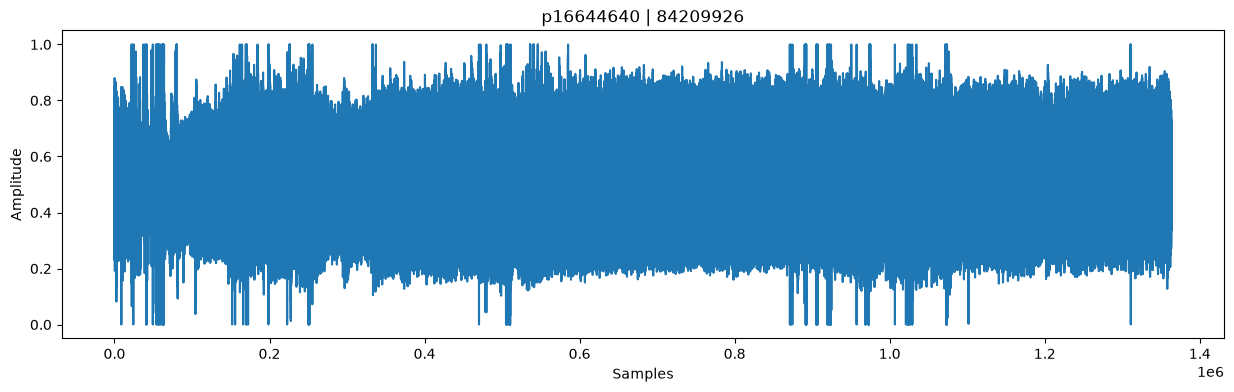

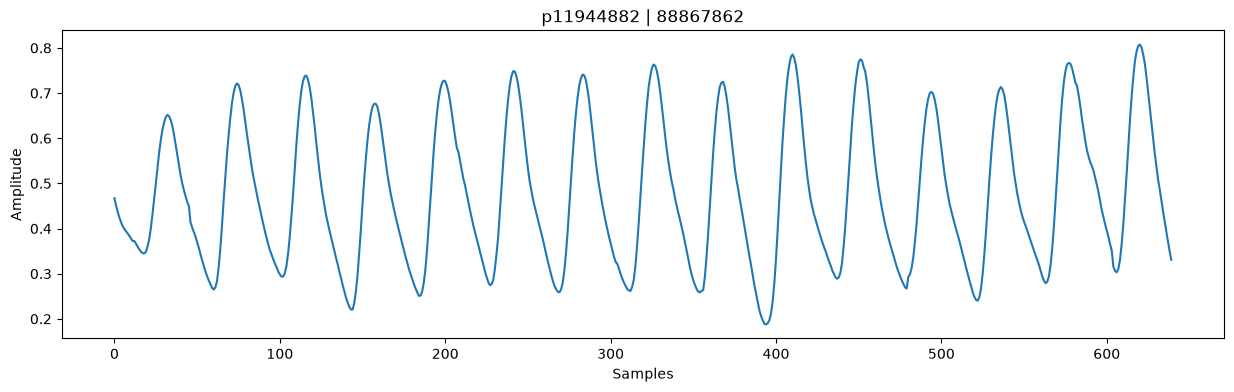

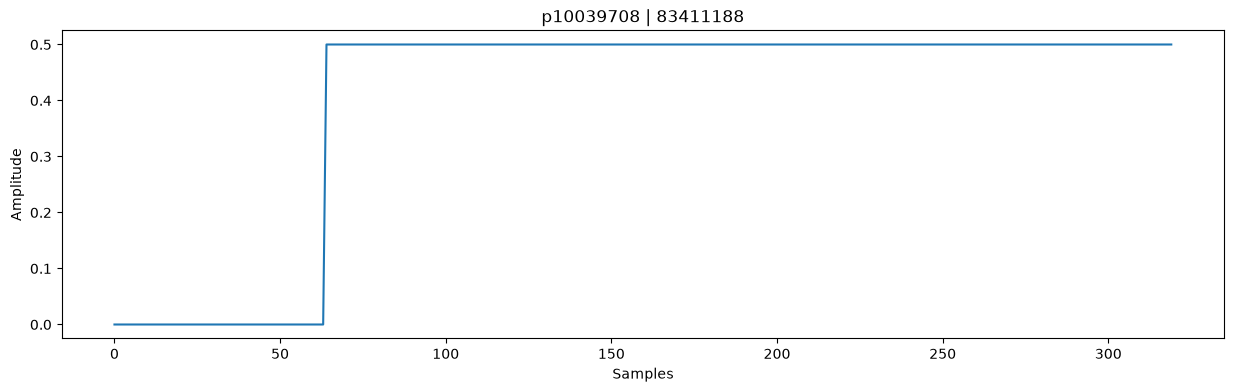

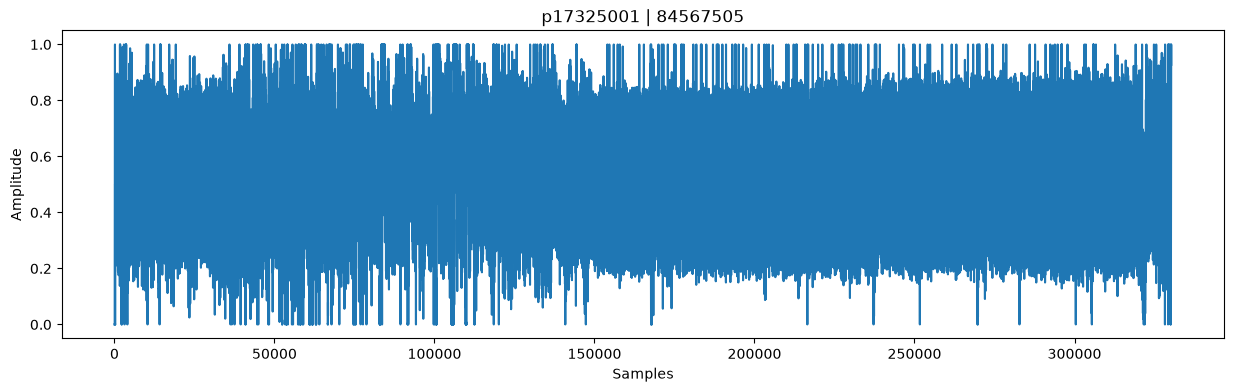

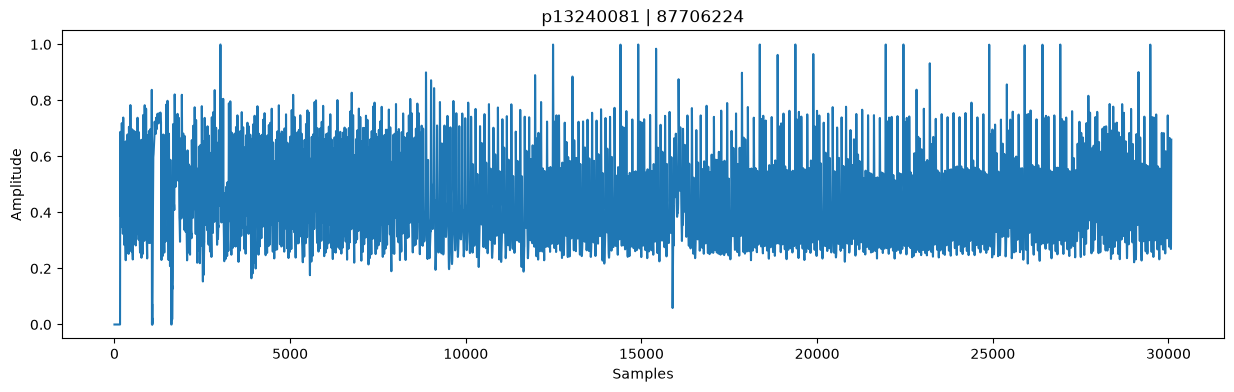

In [45]:
for record_id in five_subjects:

    row = valid_segments[
        valid_segments["record"] == record_id
    ].iloc[0]

    patient = row["patient"]
    segment = row["segment"]

    record_path = (
        WAVE_ROOT
        / f"waves/{patient[:4]}/{patient}"
        / record_id
        / segment
    )

    record = wfdb.rdrecord(str(record_path))

    channels = record.sig_name

    ppg_index = channels.index("Pleth")

    ppg = record.p_signal[:, ppg_index]

    plt.figure(figsize=(15,4))

    plt.plot(ppg)

    plt.title(f"{patient} | {record_id}")

    plt.xlabel("Samples")

    plt.ylabel("Amplitude")

    plt.show()

In [46]:
import numpy as np

valid_segments = valid_segments.copy()

valid_segments = valid_segments[
    (valid_segments["length"] >= valid_segments["fs"] * 60)
]

print(valid_segments.shape)

(551, 8)


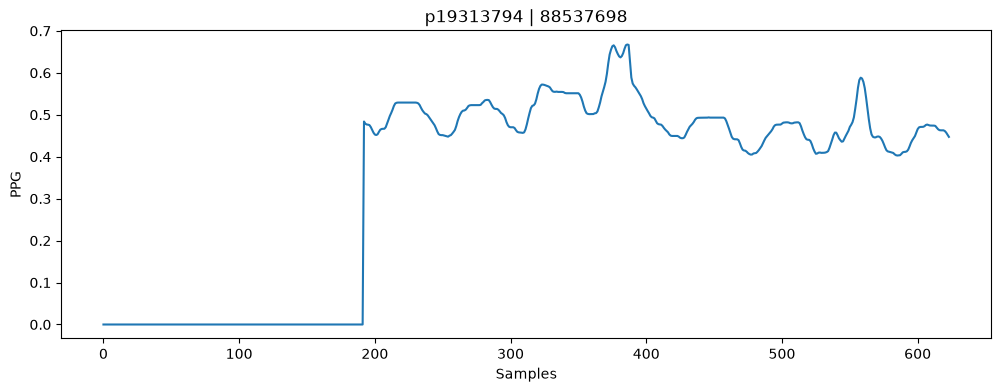

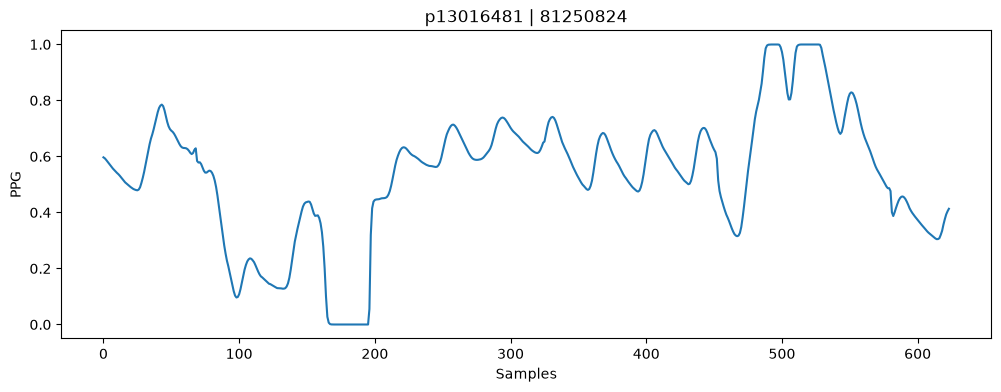

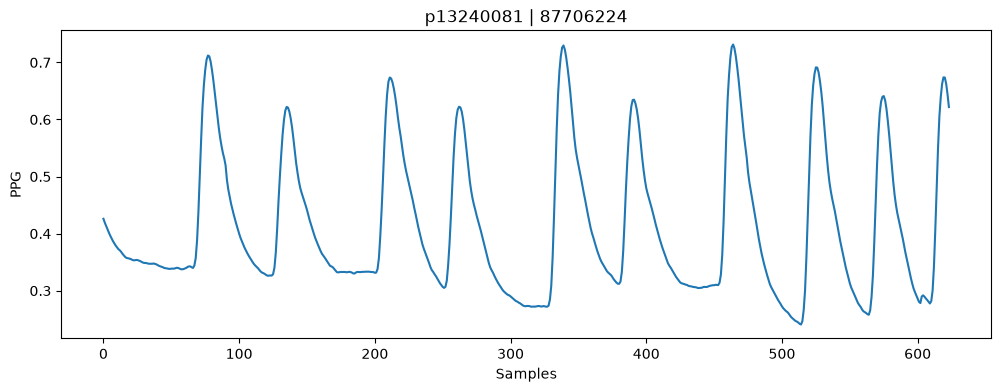

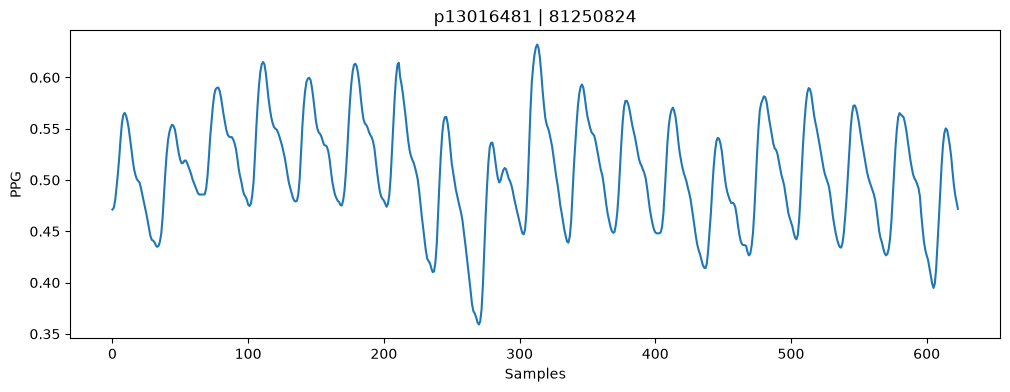

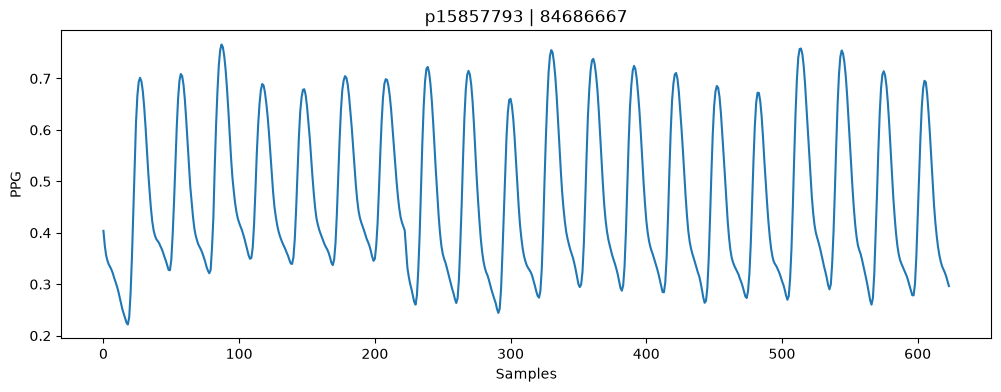

In [47]:
import matplotlib.pyplot as plt
import wfdb
import random

random.seed(42)

sample_rows = valid_segments.sample(5)

for _, row in sample_rows.iterrows():

    patient = row["patient"]
    record = row["record"]
    segment = row["segment"]

    record_path = (
        WAVE_ROOT /
        f"waves/{patient[:4]}/{patient}" /
        record /
        segment
    )

    rec = wfdb.rdrecord(str(record_path))

    ppg_index = rec.sig_name.index("Pleth")

    ppg = rec.p_signal[:, ppg_index]

    fs = rec.fs

    # Show only the first 10 seconds
    ppg = ppg[: int(fs * 10)]

    plt.figure(figsize=(12,4))
    plt.plot(ppg)
    plt.title(f"{patient} | {record}")
    plt.xlabel("Samples")
    plt.ylabel("PPG")
    plt.show()

In [48]:
from scipy.signal import butter, filtfilt

def butter_bandpass(signal, fs):

    low = 0.5
    high = 8

    nyquist = fs / 2

    b, a = butter(
        4,
        [low / nyquist, high / nyquist],
        btype="band"
    )

    return filtfilt(b, a, signal)

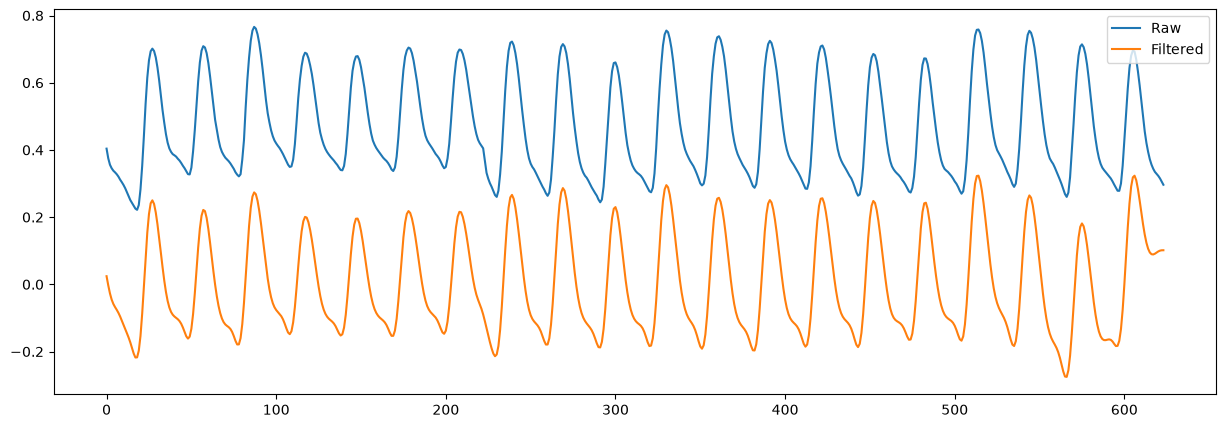

In [49]:
filtered = butter_bandpass(ppg, fs)

plt.figure(figsize=(15,5))

plt.plot(ppg, label="Raw")

plt.plot(filtered, label="Filtered")

plt.legend()

plt.show()

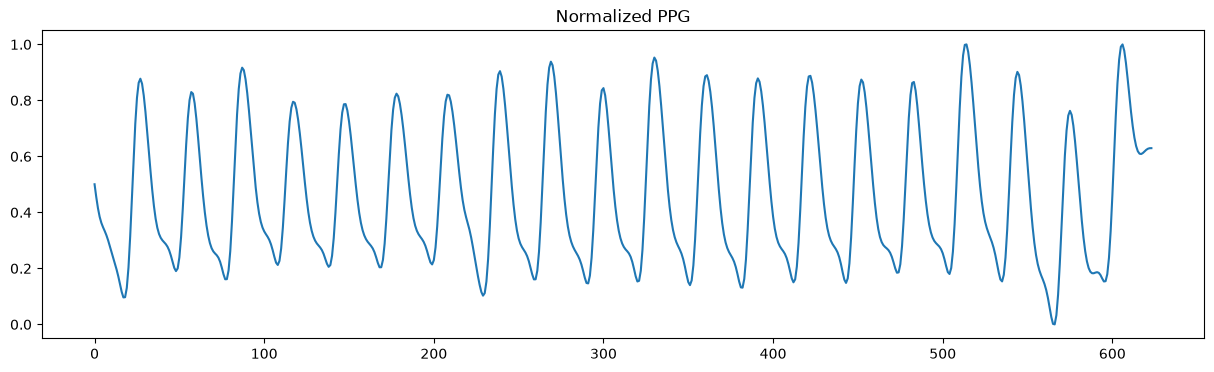

In [50]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

filtered = scaler.fit_transform(
    filtered.reshape(-1,1)
).flatten()

plt.figure(figsize=(15,4))
plt.plot(filtered)
plt.title("Normalized PPG")
plt.show()

In [51]:
from scipy.signal import butter, filtfilt
from sklearn.preprocessing import MinMaxScaler

def preprocess_ppg(ppg, fs):

    b,a = butter(
        4,
        [0.5/(fs/2),8/(fs/2)],
        btype="band"
    )

    filtered = filtfilt(b,a,ppg)

    scaler = MinMaxScaler()

    normalized = scaler.fit_transform(
        filtered.reshape(-1,1)
    ).flatten()

    return normalized

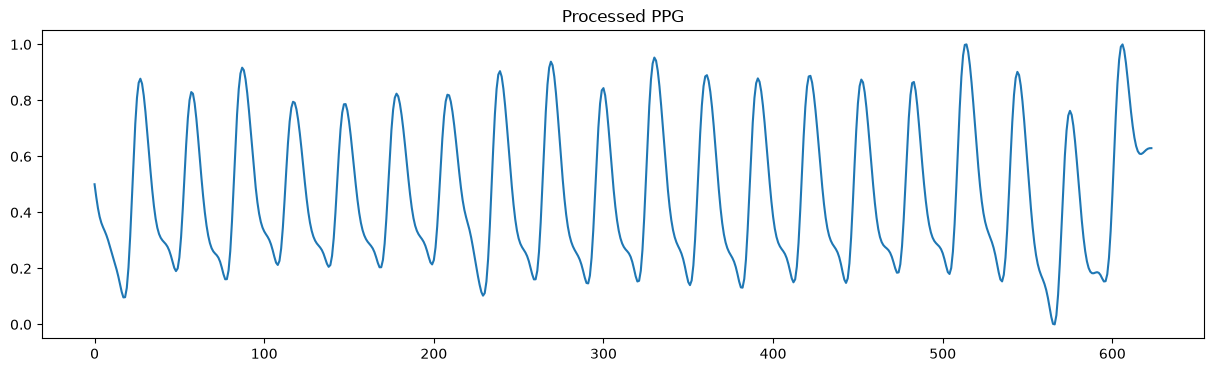

In [52]:
processed = preprocess_ppg(ppg, fs)

plt.figure(figsize=(15,4))
plt.plot(processed)
plt.title("Processed PPG")
plt.show()

In [92]:
import os

OUTPUT_DIR = "scalograms_final"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output folder ready!")

Output folder ready!


In [94]:
import shutil
import os

if os.path.exists("scalograms_final"):
    shutil.rmtree("scalograms_final")

os.makedirs("scalograms_final")

print("Folder cleaned.")

Folder cleaned.


In [96]:
import os
import cv2
import pywt
import wfdb
import numpy as np
import pandas as pd
from tqdm import tqdm

OUTPUT_DIR = "scalograms_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

WINDOW_SECONDS = 10
MAX_WINDOWS = 6

all_labels = []
saved = 0

for _, row in tqdm(valid_segments.iterrows(), total=len(valid_segments)):

    patient = row["patient"]
    record = row["record"]
    segment = row["segment"]

    record_path = (
        WAVE_ROOT /
        f"waves/{patient[:4]}/{patient}" /
        record /
        segment
    )

    try:
        rec = wfdb.rdrecord(str(record_path))
    except:
        continue

    channels = [c.upper() for c in rec.sig_name]

    if "PLETH" in channels:
        idx = channels.index("PLETH")
    elif "PPG" in channels:
        idx = channels.index("PPG")
    else:
        continue

    ppg = rec.p_signal[:, idx]

    if len(ppg) < 30:
        continue

    try:
        processed = preprocess_ppg(ppg, rec.fs)
    except Exception:
        continue

   

    WINDOW = int(WINDOW_SECONDS * rec.fs)

    if len(processed) < WINDOW:
        continue

    num_windows = min(
        MAX_WINDOWS,
        len(processed) // WINDOW
    )

    for i in range(num_windows):

        start = i * WINDOW
        end = start + WINDOW

        window = processed[start:end]

        if len(window) != WINDOW:
            continue

        coef, _ = pywt.cwt(
            window,
            np.arange(1,129),
            "morl"
        )

        img = np.abs(coef)

        img -= img.min()

        if img.max() > 0:
            img /= img.max()

        img = (img * 255).astype(np.uint8)

        img = cv2.applyColorMap(
            img,
            cv2.COLORMAP_JET
        )

        img = cv2.resize(
            img,
            (224,224),
            interpolation=cv2.INTER_AREA
        )

        filename = (
            f"{patient}_{record}_{segment}_{i}.png"
        )

        save_path = os.path.join(
            OUTPUT_DIR,
            filename
        )

        cv2.imwrite(save_path, img)

        all_labels.append({
            "image": filename,
            "SBP": row["SBP"],
            "DBP": row["DBP"]
        })

        saved += 1

labels_final = pd.DataFrame(all_labels)

labels_final.to_csv(
    "labels_final.csv",
    index=False
)

print("=" * 60)
print("Images Generated :", saved)
print("Labels Saved     :", len(labels_final))
print("=" * 60)

100%|██████████| 761/761 [08:15<00:00,  1.54it/s]

Images Generated : 3153
Labels Saved     : 3153


In [97]:
import os
import pandas as pd

labels_final = pd.read_csv("labels_final.csv")

print("="*60)
print("Images :", len(os.listdir("scalograms_final")))
print("Labels :", len(labels_final))
print("="*60)

labels_final.head()

Images : 3153
Labels : 3153


,image,SBP,DBP
0,p10020306_83404654_83404654_0005_0.png,29.1875,24.75
1,p10020306_83404654_83404654_0005_1.png,29.1875,24.75
2,p10020306_83404654_83404654_0005_2.png,29.1875,24.75
3,p10020306_83404654_83404654_0005_3.png,29.1875,24.75
4,p10020306_83404654_83404654_0005_4.png,29.1875,24.75


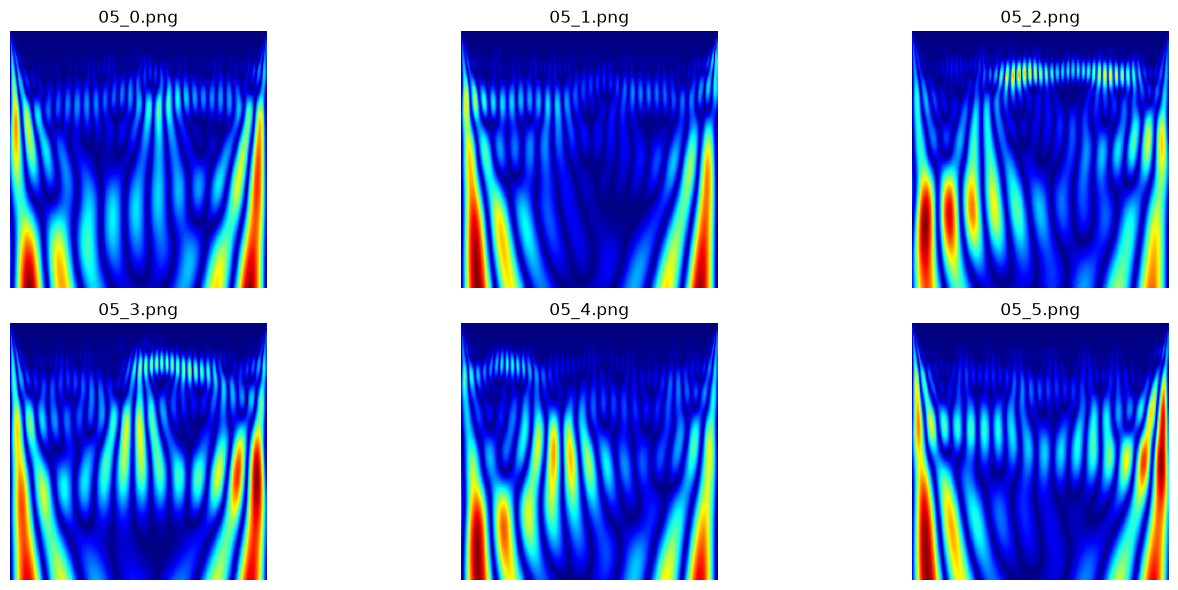

In [98]:
import os
import cv2
import matplotlib.pyplot as plt

files = sorted(os.listdir("scalograms_final"))[:6]

plt.figure(figsize=(15,6))

for i, file in enumerate(files):

    img = cv2.imread(
        os.path.join("scalograms_final", file)
    )

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(file[-8:])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [99]:
import os
import pandas as pd

labels = pd.read_csv("labels_final.csv")

print("="*60)
print("Images :", len(os.listdir("scalograms_final")))
print("Labels :", len(labels))
print("="*60)

labels.head()

Images : 3153
Labels : 3153


,image,SBP,DBP
0,p10020306_83404654_83404654_0005_0.png,29.1875,24.75
1,p10020306_83404654_83404654_0005_1.png,29.1875,24.75
2,p10020306_83404654_83404654_0005_2.png,29.1875,24.75
3,p10020306_83404654_83404654_0005_3.png,29.1875,24.75
4,p10020306_83404654_83404654_0005_4.png,29.1875,24.75


In [100]:
print(labels.describe())

print("SBP < 50 :", (labels["SBP"] < 50).sum())
print("DBP < 30 :", (labels["DBP"] < 30).sum())

               SBP          DBP
count  3153.000000  3153.000000
mean    119.974326    53.013270
std      25.071292    13.505517
min      22.971875    20.062500
25%     106.062500    45.250000
50%     118.312500    52.750000
75%     132.125000    61.125000
max     246.250000   135.625000
SBP < 50 : 58
DBP < 30 : 138
